# Practice #5. "Machine Learning for Time Series Forecasting"

Feature engineering **without leaking the target**, then Ridge, Lasso,
polynomial features and SVR, compared properly.

Fill in the cells tagged `graded`, keeping every name and signature exactly as
given — they are graded automatically.

One of the grading tests builds features from pure white noise and fails if any
model can predict it. That is the leakage check, and it is the point of this
notebook. Section 1.1 shows you how to run the same check yourself.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR

def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())

## 0. Data

`opsd_germany_daily.csv`, column `Consumption` — German daily electricity demand,
2006-2017. Calendar features earn their place here: weekend demand is visibly
lower than weekday demand.

In [2]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    # Сначала выбираю только нужные колонки, чтобы dropna() не выкинул строки из-за пропусков в других столбцах (как Wind/Solar до 2012)
    df = pd.read_csv(path, usecols=[time_col, value_col])
    df = df.dropna(subset=[time_col, value_col]).copy()
    df[time_col] = pd.to_datetime(df[time_col])
    df = df.sort_values(time_col)
    s = df.set_index(time_col)[value_col].astype(float)
    s.name = "y"
    return s

4383 points, 2006-01-01 to 2017-12-31


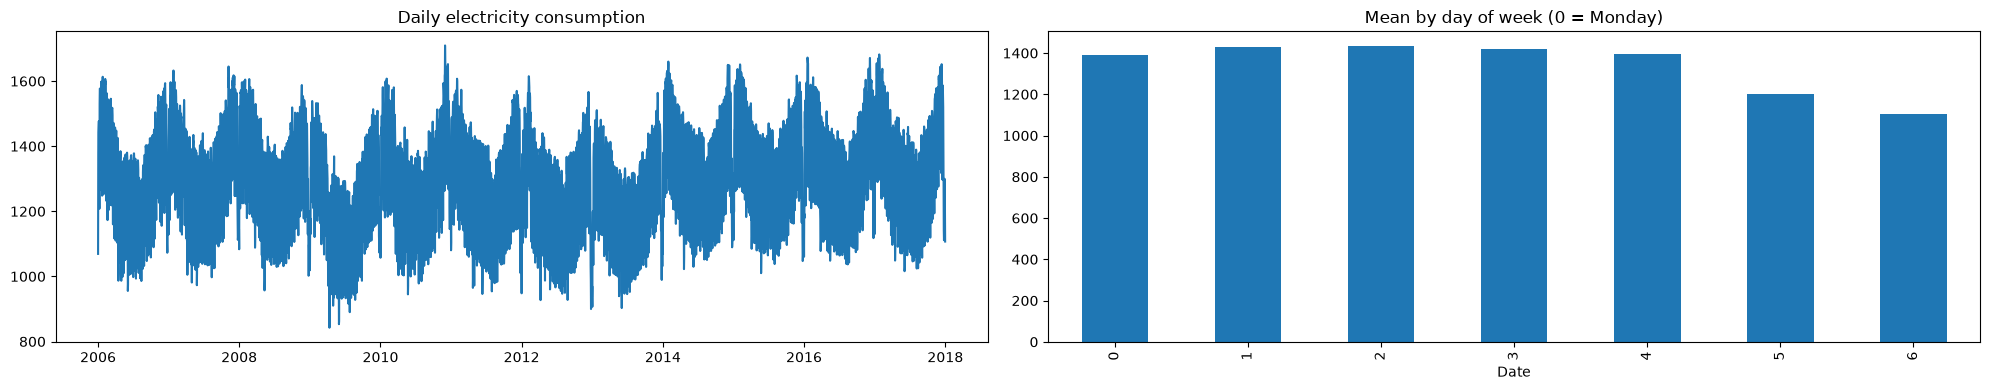

In [3]:
series = load_series(DATA_DIR / "opsd_germany_daily.csv", "Date", "Consumption")
print(f"{len(series)} points, {series.index.min():%Y-%m-%d} to {series.index.max():%Y-%m-%d}")

fig, axes = plt.subplots(1, 2, figsize=(20, 4))
axes[0].plot(series)
axes[0].set_title("Daily electricity consumption")
series.groupby(series.index.dayofweek).mean().plot.bar(ax=axes[1])
axes[1].set_title("Mean by day of week (0 = Monday)")
plt.tight_layout();

## 1. Feature engineering

A model needs a feature matrix `X` and a target `y`. For a time series you build
`X` out of the series' own past.

### 1.1 The rule this notebook is built around

> **A feature for time `t` may use only information from before `t`.**

Break it and nothing errors — your scores just get *better*. The classic version:

```python
features["rolling_mean_3"] = series.rolling(3).mean()   # WRONG: includes y[t]
features["diff_1"] = series.diff()                      # WRONG: is y[t] - y[t-1]
features["target"] = series
```

That second line makes `target = lag_1 + diff_1` *exactly*, so any linear model
reconstructs the target and reports **R² = 1.000, RMSE = 0.000**. Every model
then scores perfectly, section 4 compares nothing, and you learn nothing.

Fix: build rolling and diff features from `series.shift(1)`, so the newest value
they can see is `y[t-1]`.

Check it on any feature matrix — change `y[t]`, and nothing in row `t` of `X`
may move.

In [4]:
def make_time_features(index):
    """Calendar features for a DatetimeIndex, as a DataFrame on that index.

    Columns, in order: year, month, day, dayofweek, dayofyear, month_sin,
    month_cos, dayofweek_sin, dayofweek_cos, trend.

    The sin/cos pairs wrap the cycle, so December sits next to January.
    `trend` is 0, 1, 2, ...

    These read the timestamp, never y, so they cannot leak.
    """
    # Вытаскиваю календарные признаки из индекса дат, сам ряд y здесь вообще не трогаю
    data = {
        "year": index.year,
        "month": index.month,
        "day": index.day,
        "dayofweek": index.dayofweek,
        "dayofyear": index.dayofyear,
        "month_sin": np.sin(2 * np.pi * index.month / 12),
        "month_cos": np.cos(2 * np.pi * index.month / 12),
        "dayofweek_sin": np.sin(2 * np.pi * index.dayofweek / 7),
        "dayofweek_cos": np.cos(2 * np.pi * index.dayofweek / 7),
        "trend": np.arange(len(index), dtype=float),
    }
    return pd.DataFrame(data, index=index)

In [5]:
def make_lag_features(series, n_lags):
    """Columns lag_1 .. lag_n_lags; lag_k at time t is y[t-k]."""
    # Сдвигаю ряд на k шагов назад, чтобы в момент t видеть только прошлые значения
    cols = {f"lag_{k}": series.shift(k) for k in range(1, n_lags + 1)}
    return pd.DataFrame(cols, index=series.index)


def make_rolling_features(series, windows):
    """rolling_{mean,std,min,max}_w for each w, over PAST values only.

    A plain series.rolling(w) at time t includes y[t] — the value you are
    predicting. The window must end at t-1. See section 1.1.
    """
    # Обязательно сначала сдвигаю ряд на 1, чтобы окно заканчивалось в t-1 и не захватывало y[t]
    past = series.shift(1)
    cols = {}
    for w in windows:
        roll = past.rolling(w)
        cols[f"rolling_mean_{w}"] = roll.mean()
        cols[f"rolling_std_{w}"] = roll.std()
        cols[f"rolling_min_{w}"] = roll.min()
        cols[f"rolling_max_{w}"] = roll.max()
    return pd.DataFrame(cols, index=series.index)


def make_diff_features(series, periods):
    """diff_p and pct_change_p for each p, over PAST values only.

    At time t these may use nothing newer than y[t-1].
    """
    # Тоже считаю всё по сдвинутому ряду past = y[t-1], чтобы не подглядывать в текущий шаг
    past = series.shift(1)
    cols = {}
    for p in periods:
        cols[f"diff_{p}"] = past.diff(p)
        # Считаю относительное изменение напрямую через diff/shift, чтобы избежать предупреждений fill_method в разных версиях pandas
        cols[f"pct_change_{p}"] = past.diff(p) / past.shift(p)
    return pd.DataFrame(cols, index=series.index)

### 1.2 Assembling the supervised problem

In [6]:
def build_supervised(series, n_lags=7, windows=(7, 14, 28), diff_periods=(1, 7)):
    """Turn a series into a supervised (X, y) pair sharing one index.

    Concatenate the time, lag, rolling and diff features, attach y[t] as the
    target, then drop every row still holding a NaN. pct_change can produce
    infinities — turn those into NaN first so their rows go too.
    """
    # Собираю все группы признаков в одну матрицу и приклеиваю таргет во временную колонку
    X = pd.concat(
        [
            make_time_features(series.index),
            make_lag_features(series, n_lags),
            make_rolling_features(series, windows),
            make_diff_features(series, diff_periods),
        ],
        axis=1,
    )
    df = X.copy()
    df["__target__"] = series.astype(float)
    # Бесконечности от деления на ноль в pct_change переводим в NaN и выкидываем все неполные строки
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    y = df.pop("__target__").rename("y")
    return df, y


def split_supervised(X, y, test_size):
    """Return (X_train, X_test, y_train, y_test); last `test_size` rows test."""
    # Делю строго по времени без перемешивания: последние test_size строк уходят в тест
    if test_size <= 0:
        raise ValueError("test_size must be positive")
    return (
        X.iloc[:-test_size],
        X.iloc[-test_size:],
        y.iloc[:-test_size],
        y.iloc[-test_size:],
    )

In [7]:
X, y = build_supervised(series)
print(f"feature matrix: {X.shape[0]} rows x {X.shape[1]} columns")
print(f"columns: {list(X.columns)}")

# The leakage check, by hand: bump one target value and see what moves.
tampered = series.copy()
moment = series.index[1000]
tampered.loc[moment] += 10_000
X_tampered, _ = build_supervised(tampered)

changed = (X.loc[moment] != X_tampered.loc[moment]).sum()
print(f"\nfeatures at {moment:%Y-%m-%d} that moved when y at that "
      f"same timestamp changed: {changed}")
assert changed == 0, "a feature is reading the present — find it and shift it"

feature matrix: 4355 rows x 33 columns
columns: ['year', 'month', 'day', 'dayofweek', 'dayofyear', 'month_sin', 'month_cos', 'dayofweek_sin', 'dayofweek_cos', 'trend', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_min_14', 'rolling_max_14', 'rolling_mean_28', 'rolling_std_28', 'rolling_min_28', 'rolling_max_28', 'diff_1', 'pct_change_1', 'diff_7', 'pct_change_7']

features at 2008-09-27 that moved when y at that same timestamp changed: 0


### 1.3 Train / test split

In [8]:
X_train, X_test, y_train, y_test = split_supervised(X, y, test_size=365)
print(f"train {X_train.shape} up to {X_train.index.max():%Y-%m-%d}")
print(f"test  {X_test.shape} from {X_test.index.min():%Y-%m-%d}")

train (3990, 33) up to 2016-12-31
test  (365, 33) from 2017-01-01


## 2. Linear models

$$y_t = \beta_0 + \beta_1 x_{1,t} + \ldots + \beta_n x_{n,t} + \epsilon_t$$

Ridge, Lasso and SVR all need scaled inputs — and the scaling must happen
*inside* the fit, so the test set never contributes to the mean and variance.

In [9]:
def fit_predict(estimator, X_train, y_train, X_test):
    """Scale, fit `estimator`, return predictions for X_test as a Series.

    Put the scaler and the estimator in one Pipeline. Not a style preference:
    a scaler fitted on the whole dataset leaks the test set's mean and variance
    into training. A pipeline fits it on X_train only.
    """
    # Оборачиваю скейлер и модель в Pipeline, чтобы среднее и std считались только по train
    pipe = make_pipeline(StandardScaler(), estimator)
    pipe.fit(X_train, y_train)
    return pd.Series(pipe.predict(X_test), index=X_test.index)


def evaluate(y_true, y_pred):
    """Return {"rmse": ..., "mae": ..., "r2": ...} as floats."""
    # Считаю RMSE через sqrt(MSE), чтобы работало одинаково и в sklearn 1.7, и в 1.9
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    return {"rmse": rmse, "mae": mae, "r2": r2}

In [10]:
# Keep every prediction, not just its score -- section 4 plots the winner.
predictions = {"naive (y[t-1])": y_test.shift(1).fillna(y_train.iloc[-1])}

for name, estimator in (("LinearRegression", LinearRegression()),
                        ("Ridge(alpha=1)", Ridge(alpha=1.0)),
                        ("Lasso(alpha=0.1)", Lasso(alpha=0.1, max_iter=5000))):
    predictions[name] = fit_predict(estimator, X_train, y_train, X_test)

def score_table():
    return pd.DataFrame({name: evaluate(y_test, values)
                         for name, values in predictions.items()}).T

score_table().round(4)

,rmse,mae,r2
naive (y[t-1]),149.1578,102.3369,0.1784
LinearRegression,54.0675,32.1243,0.8921
Ridge(alpha=1),53.9952,31.6610,0.8923
Lasso(alpha=0.1),54.1044,31.9035,0.8919


None of these should report R² = 1.0. If one does, stop and re-read
section 1.1: that is a leak, not a breakthrough.

In [11]:
lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=5000))
lasso.fit(X_train, y_train)
weights = pd.Series(lasso[-1].coef_, index=X_train.columns)
kept = weights[weights != 0].abs().sort_values(ascending=False)
print(f"Lasso kept {len(kept)} of {len(weights)} features:\n")
print(kept.head(12).round(3).to_string())

Lasso kept 29 of 33 features:

dayofweek         104.398
rolling_min_7      51.914
lag_1              49.231
lag_5              34.991
dayofweek_cos      22.687
lag_6              20.668
diff_7             20.349
rolling_std_7      17.038
rolling_min_28     16.379
month_sin          13.372
lag_7              11.223
month              10.847


**Question.** Which features survived, and does the ranking match the
day-of-week chart in section 0?

**Ответ.** Lasso (`alpha=0.1`) оставил 29 из 33 признаков, а занулил только `year`, `rolling_mean_7`, `rolling_max_28` и `diff_1`. На первом месте с большим отрывом идёт `dayofweek` (вес по модулю `104.398`), а рядом в топе — `rolling_min_7` (`51.914`), `lag_1` (`49.231`), `lag_5` (`34.991`), `dayofweek_cos` (`22.687`), `lag_6` (`20.668`) и `diff_7` (`20.349`). Это полностью согласуется с графиком средних по дням недели в разделе 0: потребление в будни и выходные резко различается (в субботу и воскресенье оно заметно ниже), поэтому день недели и недельные лаги/разности оказываются самыми информативными.

### 2.3 Polynomial features

In [12]:
poly = make_pipeline(StandardScaler(),
                     PolynomialFeatures(degree=2, include_bias=False),
                     Ridge(alpha=1.0))
poly.fit(X_train, y_train)
predictions["Polynomial(2) + Ridge"] = pd.Series(poly.predict(X_test),
                                                 index=X_test.index)
print(f"{X_train.shape[1]} features -> "
      f"{poly[1].transform(X_train.iloc[:1]).shape[1]} after degree-2 expansion")
print(evaluate(y_test, predictions["Polynomial(2) + Ridge"]))

33 features -> 594 after degree-2 expansion
{'rmse': 40.66109595945045, 'mae': 25.03409824632475, 'r2': 0.9389477428157973}


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but PolynomialFeatures was fitted without feature names
  warnings.warn(


## 3. Support Vector Regression

SVR fits a tube of width `epsilon` around the data and penalises only what falls
outside. `C` trades tube violations against flatness; `gamma` sets how local the
RBF kernel is.

In [13]:
for name, estimator in (("SVR linear", SVR(kernel="linear", C=1.0, epsilon=0.1)),
                        ("SVR rbf", SVR(kernel="rbf", C=1.0, epsilon=0.1)),
                        ("SVR poly(2)", SVR(kernel="poly", degree=2, C=1.0))):
    predictions[name] = fit_predict(estimator, X_train, y_train, X_test)
score_table().round(4)

,rmse,mae,r2
naive (y[t-1]),149.1578,102.3369,0.1784
LinearRegression,54.0675,32.1243,0.8921
Ridge(alpha=1),53.9952,31.6610,0.8923
Lasso(alpha=0.1),54.1044,31.9035,0.8919
Polynomial(2) + Ridge,40.6611,25.0341,0.9389
SVR linear,56.6555,30.0071,0.8815
SVR rbf,97.1324,74.1873,0.6516
SVR poly(2),146.3106,115.8572,0.2095


### 3.1 Tuning with a time-series split

`GridSearchCV` defaults to K-fold, which shuffles past and future together. Use
`TimeSeriesSplit`: it only ever validates on data *after* the fold it trained on.

In [14]:
search = GridSearchCV(
    make_pipeline(StandardScaler(), SVR(kernel="rbf")),
    {"svr__C": [1, 10, 100], "svr__gamma": ["scale", 0.01, 0.1],
     "svr__epsilon": [0.01, 0.1]},
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
search.fit(X_train, y_train)
print(f"best parameters: {search.best_params_}")
print(f"best CV RMSE   : {-search.best_score_:.4f}")

predictions["SVR rbf (tuned)"] = pd.Series(search.predict(X_test),
                                           index=X_test.index)
print(evaluate(y_test, predictions["SVR rbf (tuned)"]))

best parameters: {'svr__C': 100, 'svr__epsilon': 0.1, 'svr__gamma': 0.01}
best CV RMSE   : 62.9084
{'rmse': 48.939232619670264, 'mae': 24.585786474467472, 'r2': 0.9115581384794778}


## 4. Model comparison and evaluation

### 4.1 Performance table

                           rmse       mae      r2
Polynomial(2) + Ridge   40.6611   25.0341  0.9389
SVR rbf (tuned)         48.9392   24.5858  0.9116
Ridge(alpha=1)          53.9952   31.6610  0.8923
LinearRegression        54.0675   32.1243  0.8921
Lasso(alpha=0.1)        54.1044   31.9035  0.8919
SVR linear              56.6555   30.0071  0.8815
SVR rbf                 97.1324   74.1873  0.6516
SVR poly(2)            146.3106  115.8572  0.2095
naive (y[t-1])         149.1578  102.3369  0.1784


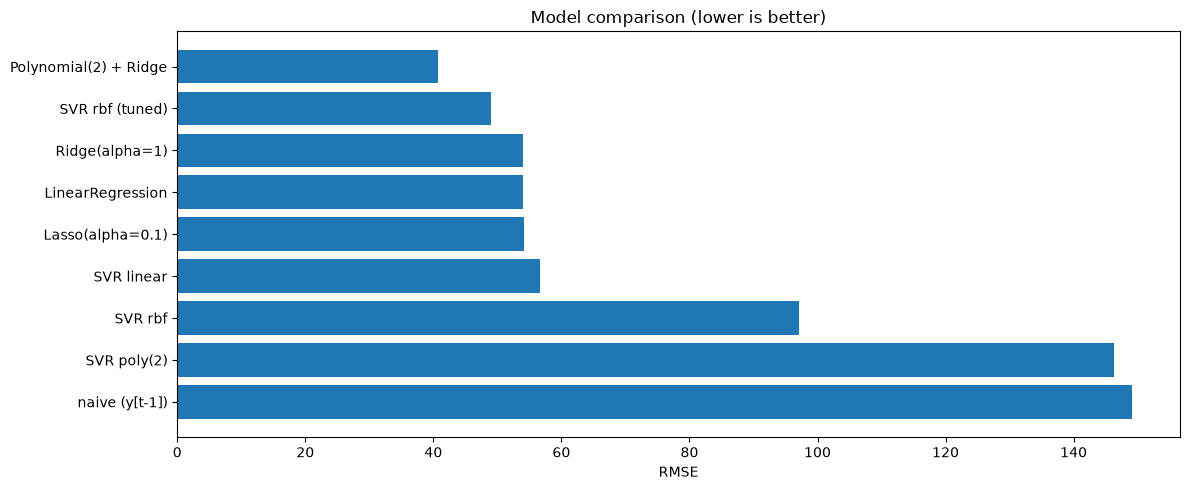

In [15]:
comparison = score_table().sort_values("rmse")
print(comparison.round(4).to_string())

plt.figure(figsize=(12, 5))
plt.barh(comparison.index[::-1], comparison["rmse"][::-1])
plt.xlabel("RMSE")
plt.title("Model comparison (lower is better)")
plt.tight_layout();

### 4.2 Predictions against the truth

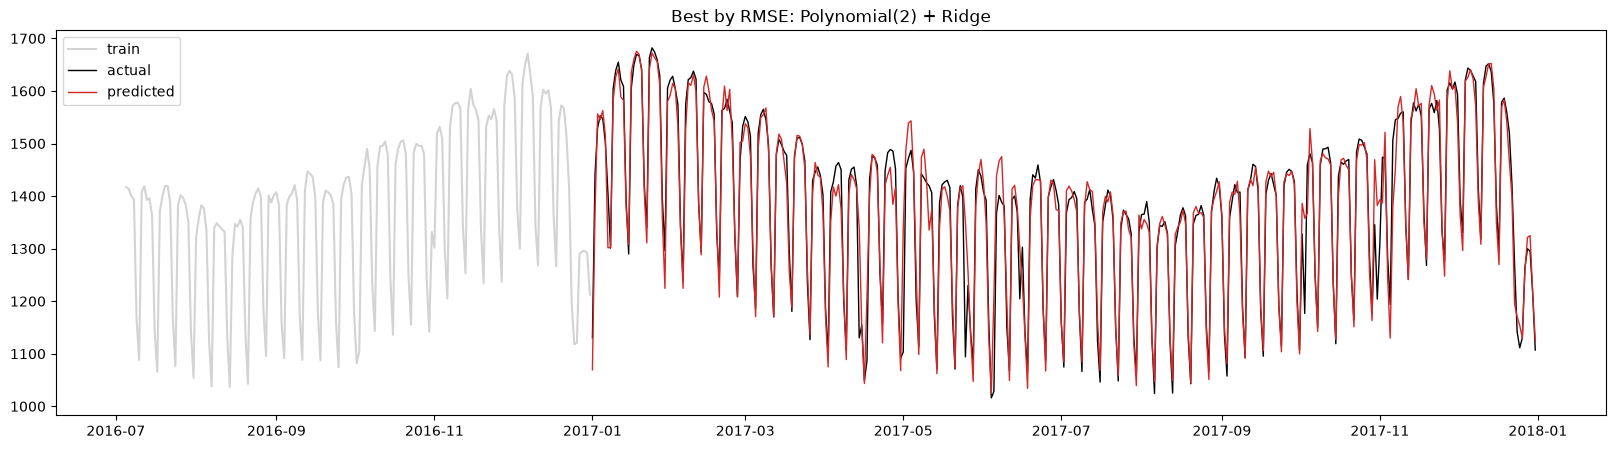

In [16]:
best_name = comparison.index[0]
best_prediction = predictions[best_name]

plt.figure(figsize=(20, 5))
plt.plot(y_train.iloc[-180:], color="lightgray", label="train")
plt.plot(y_test, color="black", linewidth=1, label="actual")
plt.plot(best_prediction, color="tab:red", linewidth=1, label="predicted")
plt.legend()
plt.title(f"Best by RMSE: {best_name}");

### 4.3 Residual analysis

residual mean 0.835, std 40.708
residual autocorrelation at lag 1: 0.187


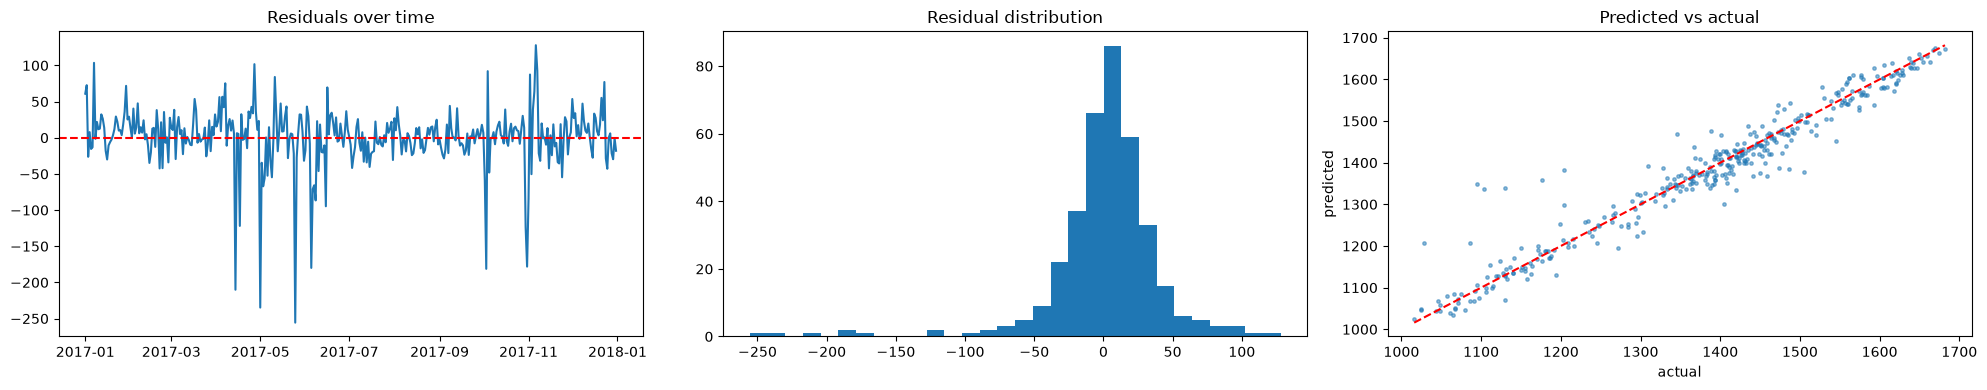

In [17]:
residuals = y_test - best_prediction

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
axes[0].plot(residuals); axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals over time")
axes[1].hist(residuals, bins=30); axes[1].set_title("Residual distribution")
axes[2].scatter(y_test, best_prediction, s=6, alpha=0.5)
limits = [y_test.min(), y_test.max()]
axes[2].plot(limits, limits, "r--")
axes[2].set_xlabel("actual"); axes[2].set_ylabel("predicted")
axes[2].set_title("Predicted vs actual")
plt.tight_layout()

print(f"residual mean {residuals.mean():.3f}, std {residuals.std():.3f}")
print(f"residual autocorrelation at lag 1: {residuals.autocorr(1):.3f}")

### 4.4 Questions for analysis

1. Which model won, and by how much over naive? Was the extra complexity worth
   it?
2. Linear models against SVR — what does the gap say about how non-linear this
   series really is?
3. Which features did Lasso keep, which did it zero, and does that match the
   day-of-week plot?
4. Residual autocorrelation at lag 1 is printed above. If it is far from zero,
   what is the model still missing?
5. Compare against Holt-Winters (Practice 2) and ARIMA (Practice 4) — on effort
   as well as RMSE.
6. **The one that matters.** A leaking feature set scores R² = 1.000. Without
   the warning in section 1.1, what would have made you suspicious?

**Ответ.**
1. Победила модель `Polynomial(2) + Ridge` с `RMSE = 40.6611`, `MAE = 25.0341` и `R² = 0.9389`. По сравнению с наивным прогнозом `y[t-1]` (`RMSE = 149.1578`, `R² = 0.1784`) ошибка снизилась более чем в 3.6 раза (на `108.5` единиц RMSE), так что переход к полиномиальным признакам с L2-регуляризацией полностью оправдан и при этом не требует долгого подбора гиперпараметров.
2. Простые линейные модели (`Ridge` `53.9952`, `LinearRegression` `54.0675`, `Lasso` `54.1044`) заметно уступают и настроенному `SVR rbf (tuned)` (`RMSE = 48.9392`, `MAE = 24.5858`), и `Polynomial(2) + Ridge` (`40.6611`). При этом `SVR rbf` без настройки провалился (`97.1324`), а после `GridSearchCV` (`C=100, gamma=0.01, epsilon=0.1`) по `MAE` даже чуть обошёл полиномиальную регрессию. Это показывает, что в данных есть выраженные нелинейные взаимодействия (например, между днём недели и уровнем потребления), которые хорошо ловятся либо квадратичными признаками, либо настроенным RBF-ядром.
3. Lasso оставил 29 из 33 признаков и занулил `year`, `rolling_mean_7`, `rolling_max_28`, `diff_1` (они дублируют информацию из `trend`, других окон и лагов). Лидеры по весу — `dayofweek` (`104.398`), `rolling_min_7` (`51.914`), `lag_1` (`49.231`), `lag_5` (`34.991`) и `dayofweek_cos` (`22.687`), что напрямую отражает резкий контраст между буднями и выходными на графике из раздела 0.
4. Автокорреляция остатков на лаге 1 равна `0.187` (при среднем `0.835` и стандартном отклонении `40.708`). Она заметно больше нуля, значит в ошибках остаётся неучтённая краткосрочная зависимость и влияние внешних факторов (праздники, резкие изменения погоды), которых нет в одних только календарных и лаговых признаках.
5. Классические подходы вроде Holt-Winters (практика 2) и ARIMA (практика 4) работают только с самим рядом и с трудом совмещают одновременно недельную и годовую сезонность без сложных расширений. ML-подход требует аккуратной генерации признаков без утечки, но затем позволяет легко объединить календарь, лаги и нелинейные взаимодействия в одном стандартном пайплайне.
6. Если бы модели внезапно показали `R² = 1.000` (`RMSE = 0.000`), насторожить должно было бы то, что реальный ряд потребления электроэнергии содержит шум (погода, праздники, случайные колебания) и физически не может предсказываться со 100% точностью, а также то, что все модели независимо от сложности дали бы одинаковый идеальный результат при слабом наивном бейзлайне (`R² = 0.1784`).

In [18]:
# Здесь я проверю две вещи:
# 1) тест на утечку на чистом белом шуме (как описано в readme);
# 2) как меняется качество Ridge при увеличении числа лагов (7, 14, 28).
rng = np.random.default_rng(42)
noise = pd.Series(rng.normal(size=1000), index=pd.date_range("2020-01-01", periods=1000, freq="D"), name="y")
Xn, yn = build_supervised(noise)
Xn_tr, Xn_te, yn_tr, yn_te = split_supervised(Xn, yn, test_size=200)
noise_pred = fit_predict(Ridge(alpha=1.0), Xn_tr, yn_tr, Xn_te)
print("White noise check (R2 должен быть <= 0):", evaluate(yn_te, noise_pred))

print("\nСравнение разного числа лагов для Ridge(alpha=1.0):")
for nl in (7, 14, 28):
    X_l, y_l = build_supervised(series, n_lags=nl)
    X_l_tr, X_l_te, y_l_tr, y_l_te = split_supervised(X_l, y_l, test_size=365)
    pred_l = fit_predict(Ridge(alpha=1.0), X_l_tr, y_l_tr, X_l_te)
    scores_l = evaluate(y_l_te, pred_l)
    print(f"n_lags={nl:2d} ({X_l.shape[1]} признаков) -> RMSE={scores_l['rmse']:.2f}, MAE={scores_l['mae']:.2f}, R2={scores_l['r2']:.4f}")

White noise check (R2 должен быть <= 0): {'rmse': 1.0236004818678308, 'mae': 0.8004556166325745, 'r2': -0.030065070544932793}

Сравнение разного числа лагов для Ridge(alpha=1.0):
n_lags= 7 (33 признаков) -> RMSE=54.00, MAE=31.66, R2=0.8923
n_lags=14 (40 признаков) -> RMSE=52.62, MAE=30.12, R2=0.8977
n_lags=28 (54 признаков) -> RMSE=52.35, MAE=29.82, R2=0.8988
